# Fiziksel Katman Jamming (Karıştırma) Tespiti ve Sınıflandırması
### GNU Radio ile üretilmiş gerçekçi RF verisi üzerinde iki aşamalı tespit + bilinmeyen jammer (açık-küme) analizi



Bu çalışmada GNU Radio Companion ile 5 sınıflık RF sinyali (1 normal + 4 jammer türü) üretilmiş, kanal modeli (çok yollu sönümleme) eklenerek gerçekçi hale getirilmiştir. Ham I/Q sinyalden öznitelikler çıkarılıp (1) saldırı var mı yok mu, (2) hangi jammer türü sorularına cevap veren iki aşamalı bir sistem kurulmuştur. Ayrıca eğitimde hiç görülmemiş bir jammer türünün yakalanıp yakalanamadığı (açık-küme) test edilmiştir.

In [2]:
import numpy as np, pandas as pd

DIR = '/kaggle/input/datasets/senanurcolayr/jamming-dat-kanal/' 
P = 1024                                    # her pencere 1024 örnek
dd   = {'normal':0, 'constant':1, 'tone':2, 'sweep':3, 'pulse':4}
isim = {0:'normal', 1:'constant', 2:'tone', 3:'sweep', 4:'pulse'}

# --- Bir sinyal penceresinden 10 öznitelik çıkaran fonksiyon ---
def feat(s):
    s = np.real(s).astype(np.float64)
    mu = np.mean(s); sd = np.std(s) + 1e-12
    z = (s - mu) / sd
    fft = np.abs(np.fft.rfft(s))
    zc = np.sum(np.abs(np.diff(np.sign(s)))) / 2          # sıfır geçiş sayısı
    za = np.abs(s)
    ze = [np.mean(za[i:i+50]) for i in range(0, len(s), 50)]  # zarf (envelope)
    return [mu, sd, np.max(np.abs(s)), np.mean(s**2),
            np.mean(z**4)-3, np.mean(z**3), zc, np.std(ze),
            int(np.argmax(fft)), np.std(fft)]

cols = ['ortalama','std','max_mutlak','enerji','basiklik','carpiklik',
        'sifir_gecis','zarf_std','baskin_frekans','spektral_yayilim']

# --- Tüm .dat dosyalarını oku, 1024'lük pencerelere böl, öznitelik çıkar ---
X, y = [], []
for ad, et in dd.items():
    v = np.fromfile(DIR + ad + '.dat', dtype=np.complex64)   # ham I/Q sinyal
    n = len(v) // P
    for i in range(n):
        X.append(feat(v[i*P:(i+1)*P])); y.append(et)
X = np.array(X); y = np.array(y)

df = pd.DataFrame(X, columns=cols); df['Etiket'] = y
df.to_csv('/kaggle/working/jamming_veri_seti_v2.csv', index=False)  # CSV kaydı

print("Toplam pencere:", len(df))
for k in range(5):
    print(f"  {isim[k]:9s}: {(y==k).sum()}")
norm = (y==0).sum(); att = (y!=0).sum()
print(f"\nNormal / Saldırı oranı: %{100*norm/len(y):.0f} / %{100*att/len(y):.0f}")
df.head()

Toplam pencere: 54984
  normal   : 22209
  constant : 8647
  tone     : 8535
  sweep    : 7771
  pulse    : 7822

Normal / Saldırı oranı: %40 / %60


,ortalama,std,max_mutlak,enerji,basiklik,carpiklik,sifir_gecis,zarf_std,baskin_frekans,spektral_yayilim,Etiket
0,0.008031,1.001401,1.909532,1.002869,-1.371832,-0.016893,72.0,0.043002,32.0,31.045359,0
1,0.007084,0.993665,1.963389,0.987420,-1.354193,-0.008817,76.0,0.042167,32.0,30.840848,0
2,0.017938,0.989636,2.038291,0.979702,-1.323837,-0.023445,72.0,0.045831,32.0,30.713581,0
3,-0.006866,0.993737,1.984908,0.987560,-1.338989,0.001780,78.0,0.065827,32.0,30.781485,0
4,-0.008098,0.985307,1.823700,0.970895,-1.317993,-0.000068,78.0,0.039393,32.0,30.559004,0


## 1. Veri Seti ve Sınıf İstatistikleri
Veri seti 1024 örneklik pencerelere bölünerek elde edilmiştir. Normal trafik en büyük sınıftır; gerçekçi %80/%20 dengesizliği değerlendirme aşamasında kurulur. Aşağıda her sınıfın ortalama öznitelikleri verilmiştir.

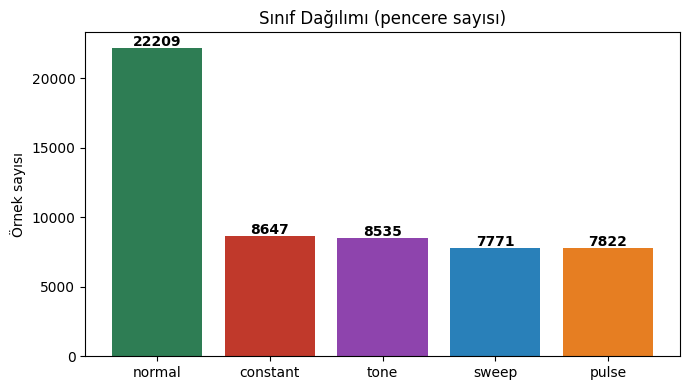

HER SINIF İÇİN ORTALAMA ÖZNİTELİKLER
           std  enerji  basiklik  zarf_std  baskin_frekans  spektral_yayilim
normal    1.00    1.00     -1.34      0.05           32.00             30.94
constant  1.42    2.13     -0.55      0.12           32.00             34.29
tone      1.43    2.19     -0.92      0.05           91.78             44.87
sweep     1.39    1.95     -0.71      0.14           32.00             36.17
pulse     1.38    1.96     -0.37      0.16           32.00             33.75


,std,enerji,basiklik,zarf_std,baskin_frekans,spektral_yayilim
normal,1.00,1.00,-1.34,0.05,32.00,30.94
constant,1.42,2.13,-0.55,0.12,32.00,34.29
tone,1.43,2.19,-0.92,0.05,91.78,44.87
sweep,1.39,1.95,-0.71,0.14,32.00,36.17
pulse,1.38,1.96,-0.37,0.16,32.00,33.75


In [2]:
import matplotlib.pyplot as plt
renkler=['#2E7D54','#C0392B','#8E44AD','#2980B9','#E67E22']
sayilar=[(y==k).sum() for k in range(5)]
plt.figure(figsize=(7,4))
bars=plt.bar([isim[k] for k in range(5)],sayilar,color=renkler)
plt.title('Sınıf Dağılımı (pencere sayısı)');plt.ylabel('Örnek sayısı')
for b,s in zip(bars,sayilar): plt.text(b.get_x()+b.get_width()/2,s+150,str(s),ha='center',fontweight='bold')
plt.tight_layout();plt.savefig('/kaggle/working/sinif_dagilimi.png',dpi=130);plt.show()

stat=df.groupby('Etiket')[['std','enerji','basiklik','zarf_std','baskin_frekans','spektral_yayilim']].mean().round(2)
stat.index=[isim[i] for i in stat.index]
print("HER SINIF İÇİN ORTALAMA ÖZNİTELİKLER");print(stat.to_string())
stat

## 2. İki Aşamalı Tespit Sistemi
Gerçekçi %80 normal / %20 saldırı değerlendirme seti kurulur. **Aşama 1:** saldırı var mı yok mu? Hem sadece-normalle eğitilen bir anomali tespiti (Isolation Forest), hem de karşılaştırma için denetimli bir Random Forest ile. **Aşama 2:** saldırı tespit edildiyse hangi tür? (Random Forest)

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import accuracy_score, classification_report, recall_score
np.random.seed(42)

# --- Gerçekçi 80/20 set: tüm normal + saldırıları normalin 1/4'üne indir ---
idx_n=np.where(y==0)[0]; idx_a=np.where(y!=0)[0]
np.random.shuffle(idx_a); idx_a=idx_a[:len(idx_n)//4]
sel=np.concatenate([idx_n,idx_a]); Xb,yb=X[sel],y[sel]; bb=(yb!=0).astype(int)
print(f"80/20 set: {len(Xb)} örnek  ->  normal %{100*(bb==0).mean():.0f} / saldırı %{100*(bb==1).mean():.0f}")

Xtr,Xte,ytr,yte=train_test_split(Xb,yb,test_size=0.3,random_state=42,stratify=yb)
btr=(ytr!=0).astype(int); bte=(yte!=0).astype(int)

# === AŞAMA 1a: ANOMALİ TESPİTİ (sadece normalle eğitilir) ===
iso=IsolationForest(n_estimators=200,contamination=0.05,random_state=42).fit(Xtr[ytr==0])
p_iso=(iso.predict(Xte)==-1).astype(int)
print("\n[Aşama 1a] ANOMALİ TESPİTİ (sadece normalle eğitildi):")
print(f"  Doğruluk %{accuracy_score(bte,p_iso)*100:.1f} | Saldırı yakalama %{recall_score(bte,p_iso)*100:.1f} | Yanlış alarm %{100*((p_iso==1)&(bte==0)).sum()/(bte==0).sum():.1f}")

# === AŞAMA 1b: DENETİMLİ İKİLİ RF (karşılaştırma) ===
rfb=RandomForestClassifier(n_estimators=200,class_weight='balanced',random_state=42).fit(Xtr,btr)
pb=rfb.predict(Xte)
print(f"[Aşama 1b] Denetimli ikili RF: doğruluk %{accuracy_score(bte,pb)*100:.1f} | saldırı yakalama %{recall_score(bte,pb)*100:.1f}")

# === AŞAMA 2: TÜR SINIFLANDIRMA (saldırılar arasında) ===
mtr=ytr!=0; mte=yte!=0
rft=RandomForestClassifier(n_estimators=200,class_weight='balanced',random_state=42).fit(Xtr[mtr],ytr[mtr])
pt=rft.predict(Xte[mte])
print(f"\n[Aşama 2] TÜR SINIFLANDIRMA: doğruluk %{accuracy_score(yte[mte],pt)*100:.1f}")
print(classification_report(yte[mte],pt,target_names=[isim[i] for i in [1,2,3,4]],zero_division=0))

80/20 set: 27761 örnek  ->  normal %80 / saldırı %20

[Aşama 1a] ANOMALİ TESPİTİ (sadece normalle eğitildi):
  Doğruluk %95.3 | Saldırı yakalama %95.7 | Yanlış alarm %4.8
[Aşama 1b] Denetimli ikili RF: doğruluk %98.8 | saldırı yakalama %95.1

[Aşama 2] TÜR SINIFLANDIRMA: doğruluk %89.1
              precision    recall  f1-score   support

    constant       0.80      0.81      0.80       441
        tone       0.98      0.99      0.98       447
       sweep       1.00      1.00      1.00       388
       pulse       0.79      0.76      0.78       390

    accuracy                           0.89      1666
   macro avg       0.89      0.89      0.89      1666
weighted avg       0.89      0.89      0.89      1666



## 3. Açık-Küme: Bilinmeyen Jammer Tespiti (Yenilik)
Gerçek 5G/6G ortamında daha önce görülmemiş yeni jammer türleri ortaya çıkabilir. Bunu test etmek için **pulse türünü eğitimden tamamen sakladık**. Denetimli bir model bilinmeyen türü yanlış bir sınıfa atamak zorundadır; anomali tabanlı aşamamız ise onu hiç görmeden "anormal/saldırı" olarak yakalayabilir.

In [4]:
SAKLI=4  # pulse saklanıyor
known=y!=SAKLI
Xk,yk=X[known],y[known]; Xp=X[y==SAKLI]       # pulse: modele hiç gösterilmedi
Xk_tr,Xk_te,yk_tr,yk_te=train_test_split(Xk,yk,test_size=0.3,random_state=42,stratify=yk)

rf_os=RandomForestClassifier(n_estimators=200,class_weight='balanced',random_state=42).fit(Xk_tr,yk_tr)
pp=rf_os.predict(Xp)
print("[Kapalı-küme DENETİMLİ RF] Bilinmeyen pulse'u neye benzetti?")
for k in range(5):
    c=(pp==k).sum()
    if c>0: print(f"   {isim[k]:9s}: %{100*c/len(pp):.1f}")
print(f"   -> NORMAL (güvenli) sanma: %{100*(pp==0).mean():.1f}  (tamamen kaçırılan saldırı)")

Xn=X[y==0]; Xn_a,Xn_b=train_test_split(Xn,test_size=0.3,random_state=42)
iso2=IsolationForest(n_estimators=200,contamination=0.05,random_state=42).fit(Xn_a)
print(f"\n[ANOMALİ TESPİTİ] Bilinmeyen pulse'u SALDIRI olarak yakalama: %{100*(iso2.predict(Xp)==-1).mean():.1f}")
print(f"   (Normalde yanlış alarm: %{100*(iso2.predict(Xn_b)==-1).mean():.1f})")

[Kapalı-küme DENETİMLİ RF] Bilinmeyen pulse'u neye benzetti?
   normal   : %1.7
   constant : %98.1
   tone     : %0.2
   -> NORMAL (güvenli) sanma: %1.7  (tamamen kaçırılan saldırı)

[ANOMALİ TESPİTİ] Bilinmeyen pulse'u SALDIRI olarak yakalama: %98.2
   (Normalde yanlış alarm: %5.3)


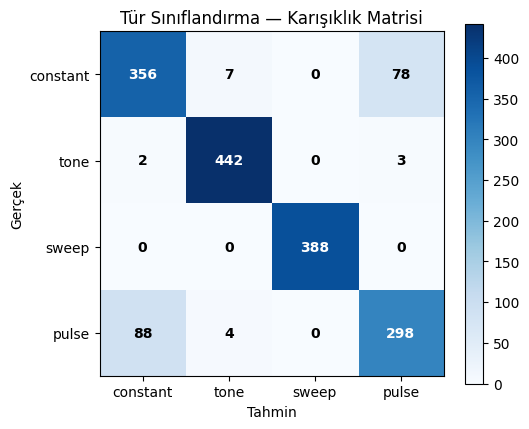

In [5]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(yte[mte],pt); etk=[isim[i] for i in [1,2,3,4]]
plt.figure(figsize=(5.5,4.5)); plt.imshow(cm,cmap='Blues')
plt.xticks(range(4),etk); plt.yticks(range(4),etk)
plt.xlabel('Tahmin'); plt.ylabel('Gerçek'); plt.title('Tür Sınıflandırma — Karışıklık Matrisi')
for i in range(4):
    for j in range(4):
        plt.text(j,i,cm[i,j],ha='center',va='center',
                 color='white' if cm[i,j]>cm.max()/2 else 'black',fontweight='bold')
plt.colorbar(); plt.tight_layout(); plt.savefig('/kaggle/working/karisiklik_tur.png',dpi=130); plt.show()

### 3.1. Açık-Küme Genelleme Testi (her tür sırayla bilinmeyen)
Yöntemin tek bir türe bağlı olmadığını göstermek için dört saldırı türü tek tek eğitimden çıkarılıp bilinmeyen kabul edilmiştir.

In [6]:
# 80-20 oranındaki csv dosyası

df80=pd.DataFrame(Xb,columns=cols); df80['Etiket']=yb
df80['Sinif']=[isim[i] for i in yb]
df80.to_csv('/kaggle/working/jamming_veri_seti_80_20.csv',index=False)
print("Kaydedildi: jamming_veri_seti_80_20.csv", df80.shape)
print(df80['Sinif'].value_counts())

Kaydedildi: jamming_veri_seti_80_20.csv (27761, 12)
Sinif
normal      22209
tone         1490
constant     1469
pulse        1300
sweep        1293
Name: count, dtype: int64
